<a href="https://colab.research.google.com/github/xtianu/Docencia/blob/main/UPC/DAPR/S4.%20Flipped%20classroom/S4_FlippedClassroom_Exercises_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


# Disclaimer : AI has been used to code and correct the code. The explanations are given as per my understanding of the process.**bold text**

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

### Exercise 1 — Step 0: imports and loading the data
**What:** load the libraries and the penguins table (344 rows, one per penguin).
**Why:** `pandas` holds tables (DataFrames), `seaborn`/`matplotlib` draw plots (Lecture 2: *always look at the data*), and `sklearn` gives us k-means, scaling and the evaluation metrics (Lecture 3).


In [7]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
print(penguins.shape)
penguins.head()        # Just checking first 5 rows

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


  ### a) Missing values
Requirement : Check how many missing values exist per column. Then drop those and confirm data is clean

Method :

*   Used Print for a heading. Then used print with coulmn name and isna and sum to give missing values per column. This gives the 'before' values.

*   Then used dropna for 'after' values and listed them using Print command.








In [8]:
print("Missing values per column (before):")
print(penguins[num_cols].isna().sum())

penguins_clean = penguins.dropna(subset=num_cols).copy()

print("\nMissing values per column (after):")
print(penguins_clean[num_cols].isna().sum())
print("\nRows before:", len(penguins), " rows after:", len(penguins_clean))

Missing values per column (before):
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Missing values per column (after):
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Rows before: 344  rows after: 342


### b) Normalization
Requirement : Scale the 4 numeric columns so they are comparable before k-means.
Method :
*   Used StandardScaler and fit_transform on the 4 columns. This makes every column have mean 0 and standard deviation 1.
*   Put the result in a new dataframe and printed the mean and std to check they are 0 and 1.
*   Reason: k-means uses Euclidean distance. Body mass is in thousands (g) and bills in tens (mm), so without scaling body mass would deci

In [9]:
scaler = StandardScaler()
scaled_values = scaler.fit_transform(penguins_clean[num_cols])
penguins_scaled_df = pd.DataFrame(scaled_values, columns=num_cols)

print(penguins_scaled_df.mean().round(2))
print(penguins_scaled_df.std(ddof=0).round(2))

bill_length_mm       0.0
bill_depth_mm       -0.0
flipper_length_mm   -0.0
body_mass_g          0.0
dtype: float64
bill_length_mm       1.0
bill_depth_mm        1.0
flipper_length_mm    1.0
body_mass_g          1.0
dtype: float64


### c) K-means
Requirement : Apply k-means with 3 clusters on the normalized data. Store labels in a variable

Method :
*   Used KMeans with n_clusters=3, n_init=10 runs it 10 times from different starting centres and keeps the best, random_state=42 gives the same result every time.

*   Printed the first labels and how many penguins are in each cluster.



In [19]:
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Fallback setup if previous cells haven't been run
if 'penguins_scaled_df' not in locals():
    penguins = sns.load_dataset('penguins')
    num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
    penguins_clean = penguins.dropna(subset=num_cols).copy()
    scaler = StandardScaler()
    scaled_values = scaler.fit_transform(penguins_clean[num_cols])
    penguins_scaled_df = pd.DataFrame(scaled_values, columns=num_cols)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
k_means_labels = kmeans.fit_predict(penguins_scaled_df)

# Print the first 10 labels
print("First 10 cluster labels:", k_means_labels[:10])

# Print how many penguins are in each cluster
print("\nPenguin counts per cluster:")
print(pd.Series(k_means_labels).value_counts().sort_index())


First 10 cluster labels: [2 2 2 2 2 2 2 2 0 2]

Penguin counts per cluster:
0     87
1    123
2    132
Name: count, dtype: int64


### d) Visualization
Requirement : Add the labels to the dataframe, make a scatterplot and two pairplots.

Method :
*   Added k_means_labels as a new column in penguins_clean (the unscaled data, so the axes show real mm and g).
*   Scatterplot of bill length vs flipper length, coloured by cluster (hue).
*   Two pairplots of the 4 variables: one coloured by real species, one by k-means cluster, to compare them visually.


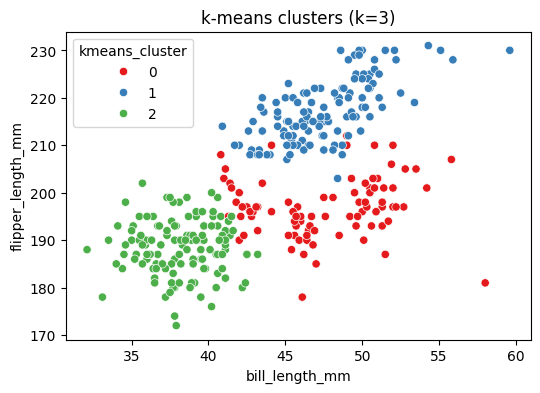

In [20]:
penguins_clean['kmeans_cluster'] = k_means_labels

plt.figure(figsize=(6, 4))
sns.scatterplot(data=penguins_clean, x='bill_length_mm', y='flipper_length_mm',
                hue='kmeans_cluster', palette='Set1')
plt.title('k-means clusters (k=3)')
plt.show()

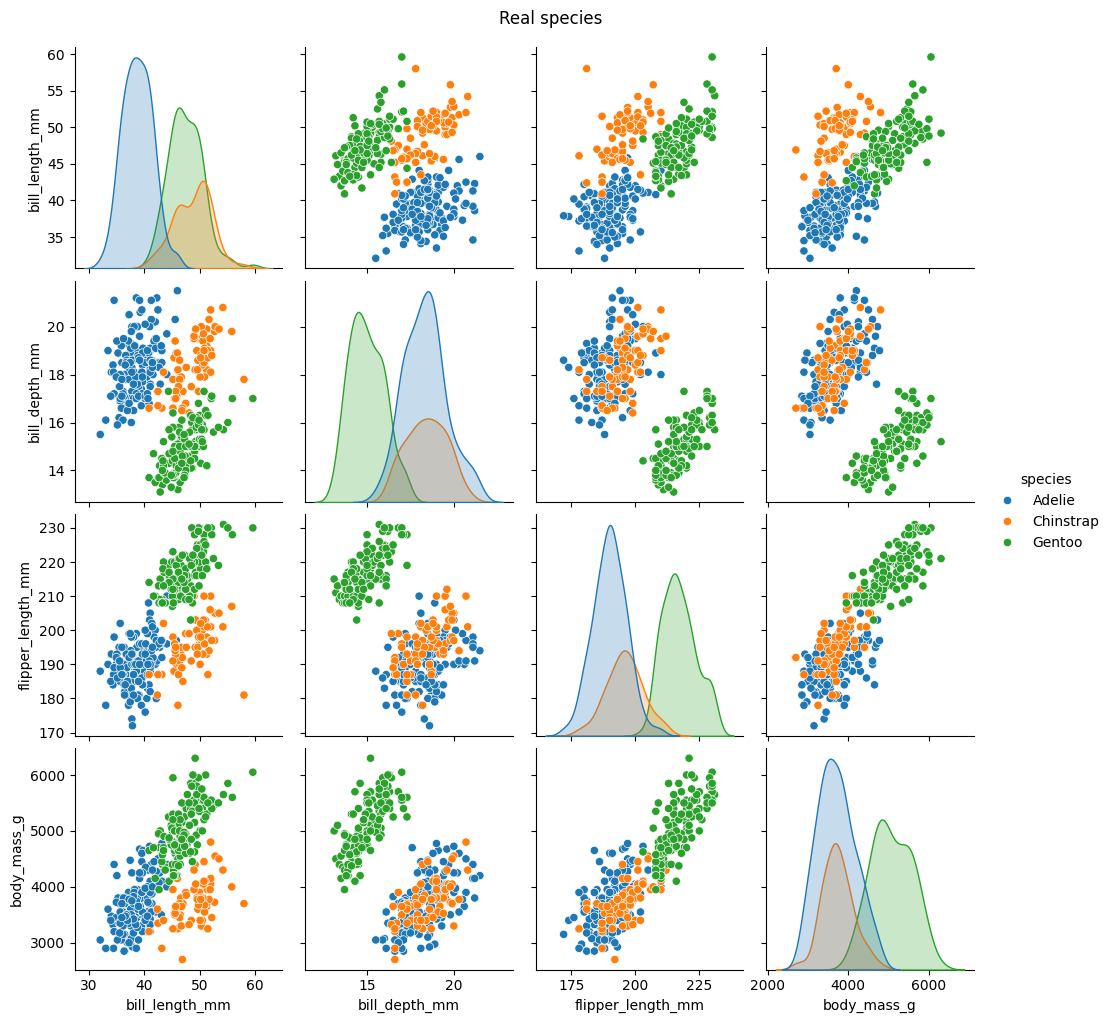

In [15]:
sns.pairplot(penguins_clean, vars=num_cols, hue='species')
plt.suptitle('Real species', y=1.02)
plt.show()

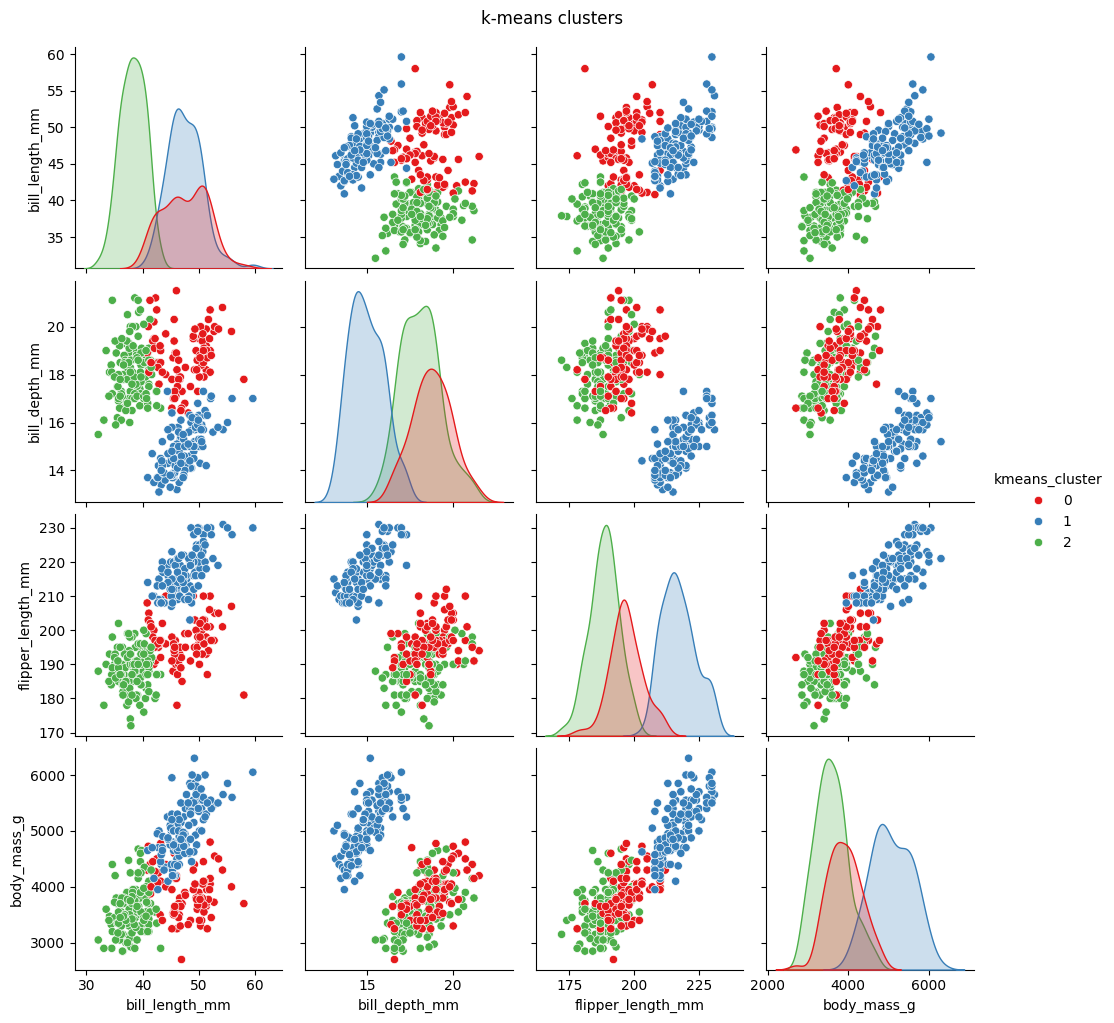

In [16]:
sns.pairplot(penguins_clean, vars=num_cols, hue='kmeans_cluster', palette='Set1')
plt.suptitle('k-means clusters', y=1.02)
plt.show()

### e) Comparison with real species
Requirement : Compare clusters with the real species using a confusion matrix and the Adjusted Rand Score.

Method :
*   Used LabelEncoder to turn species names into numbers (0, 1, 2).
*   confusion_matrix shows how many penguins of each species fell in each cluster. Cluster numbers are only names, so the table can look shuffled.
*   adjusted_rand_score gives one number for the agreement (1 = perfect, 0 = random), ignoring the cluster names. Result: 0.79.
*   Extra: ran k-means again without scaling. ARI dropped to 0.31, which shows why normalization matters.


In [22]:
le = LabelEncoder()
true_labels = le.fit_transform(penguins_clean['species'])
print("Encoding:", dict(zip(le.classes_, range(3))))

cm = confusion_matrix(true_labels, k_means_labels)
print("Confusion matrix (rows = species, cols = cluster):")
print(pd.DataFrame(cm, index=le.classes_, columns=['cluster 0', 'cluster 1', 'cluster 2']))

ari = adjusted_rand_score(true_labels, k_means_labels)
print("\nAdjusted Rand Score (scaled data):", round(ari, 3))

Encoding: {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}
Confusion matrix (rows = species, cols = cluster):
           cluster 0  cluster 1  cluster 2
Adelie            24          0        127
Chinstrap         63          0          5
Gentoo             0        123          0

Adjusted Rand Score (scaled data): 0.793


**Extra check for question f):** run the same k-means on the **raw (unscaled)** values to see what normalizing changed.


In [ ]:
kmeans_raw = KMeans(n_clusters=3, n_init=10, random_state=42)
raw_labels = kmeans_raw.fit_predict(penguins_clean[num_cols])
print(pd.DataFrame(confusion_matrix(true_labels, raw_labels),
                   index=le.classes_, columns=['cluster 0', 'cluster 1', 'cluster 2']))
print("ARI raw (unscaled):", round(adjusted_rand_score(true_labels, raw_labels), 3))

### f) Interpretation
*   Mostly Yes. Gentoo forms one pure cluster (123 penguins), because they are much bigger and have longer flippers.
*   Adelie and Chinstrap get partly mixed (24 Adelie in the Chinstrap cluster, 5 Chinstrap in the Adelie cluster), because they are similar in size and differ mainly in bill length.
*   K-means looks for round, well-separated groups, so overlapping groups like these are hard for it to split. But scaling helped in making meaningful sense of the data in different units.


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

### Exercise 2 — Step 0: imports and the toy data



In [24]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

### a) Missing values
Requirement : Check the array X has no missing values.

Method :
*   Used np.isnan(X).any(), which returns True if any value is missing. Result: False, so the data is clean.


In [25]:
print("Any missing values?", np.isnan(X).any())

Any missing values? False


### b) Normalization
Requirement : Scale X before clustering.

Method :
*   Used StandardScaler and fit_transform on X, giving X_scaled (mean 0, std 1 per column). Done as good practice for any distance-based method.


In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.round(3))

[[-1.    -0.234]
 [-1.     0.701]
 [-1.    -1.168]
 [ 1.     1.635]
 [ 1.     0.234]
 [ 1.    -1.168]]


### c) Euclidean distance function
Requirement : Write my own distance function with a for loop, no numpy.

Method :
*   Started a total at 0. Looped over each coordinate, took the difference between the two points, squared it and added it to the total.
*   Returned the square root of the total (total ** 0.5). This is Pythagoras theorem.
*   Tested on X[0] and X[3]: 5.657, same as np.linalg.norm, so the function is correct.


In [27]:
def euclidean_distance(p1, p2):
    total = 0
    for i in range(len(p1)):
        diff = p1[i] - p2[i]
        total = total + diff * diff
    return total ** 0.5

print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

5.656854249492381
5.656854249492381


### d) Agglomerative clustering + dendrogram
Requirement : Apply hierarchical clustering with 2 clusters and plot the dendrogram.

Method :
*   Used AgglomerativeClustering with n_clusters=2 on X_scaled to get agglo_labels.
*   Used linkage (Ward method) and dendrogram from scipy to draw the merge tree. The height of each join shows how far apart the merged groups were.


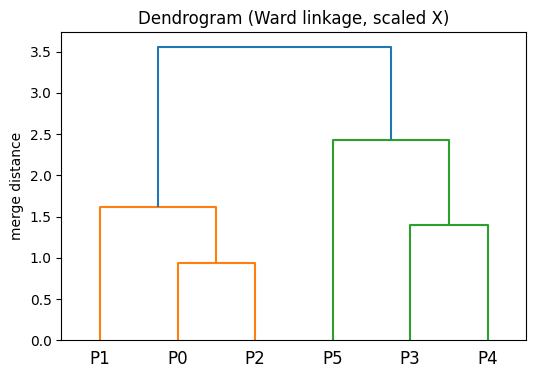

In [28]:
agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)

Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(6, 4))
dendrogram(Z, labels=[f'P{i}' for i in range(len(X))])
plt.title('Dendrogram (Ward linkage, scaled X)')
plt.ylabel('merge distance')
plt.show()

### e) K-means
Requirement : Apply k-means with 2 clusters on the same data.

Method :
*   Used KMeans with n_clusters=2, n_init=10, random_state=42 on X_scaled to get kmeans_labels.


In [30]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

### f) Comparison
Requirement : Compare both results.

Method :
*   Printed both label arrays: agglomerative & k-means.
*   They look different but are the same grouping with the names swapped. Adjusted Rand Score between them = 1.0 confirms this.
*   Plotted both side by side: both split the points into the left group (x=1) and right group (x=5).



Agglomerative: [1 1 1 0 0 0]
k-means:       [0 0 0 1 1 1]
ARI between the two (1 = same grouping): 1.0


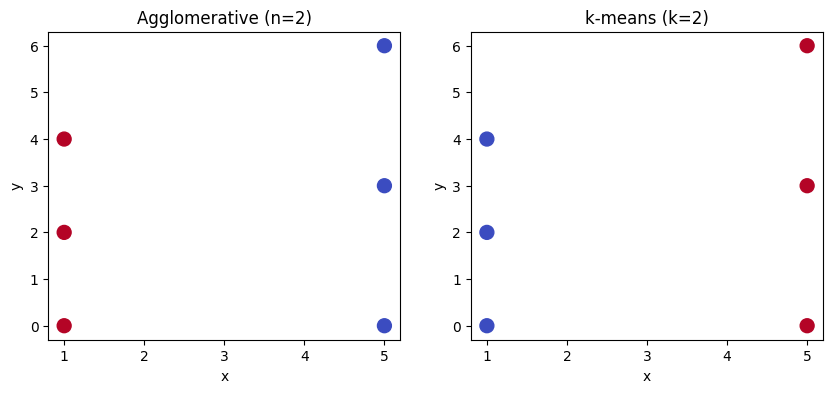

In [31]:
print("Agglomerative:", agglo_labels)
print("k-means:      ", kmeans_labels)
from sklearn.metrics import adjusted_rand_score
print("ARI between the two (1 = same grouping):", adjusted_rand_score(agglo_labels, kmeans_labels))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap='coolwarm', s=100)
axes[0].set_title('Agglomerative (n=2)')
axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='coolwarm', s=100)
axes[1].set_title('k-means (k=2)')
for ax in axes:
    ax.set_xlabel('x'); ax.set_ylabel('y')
plt.show()

### g) Cluster sizes with a dictionary
Requirement : Count points per cluster using a dictionary.

Method :
*   Made an empty dictionary. Looped over the labels: if the label is already a key, add 1, otherwise create it with value 1.
*   Result: both methods give 2 clusters of 3 points.


In [32]:
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        label = int(label)
        if label in counts:
            counts[label] = counts[label] + 1
        else:
            counts[label] = 1
    return counts

print("Agglomerative sizes:", cluster_sizes(agglo_labels))
print("k-means sizes:      ", cluster_sizes(kmeans_labels))

Agglomerative sizes: {1: 3, 0: 3}
k-means sizes:       {0: 3, 1: 3}


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

In [33]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


### a) Data selection and missing values
Requirement : Select carat, depth, table, price and check for missing values.

Method :
*   Selected the 4 columns into diamonds_num. Used isna, .sum before and after dropna.
*   No missing values, all 1000 rows kept.


In [34]:
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']].copy()
print("Missing before:\n", diamonds_num.isna().sum())
diamonds_num = diamonds_num.dropna()
print("\nMissing after:\n", diamonds_num.isna().sum())
print("Rows:", len(diamonds_num))

Missing before:
 carat    0
depth    0
table    0
price    0
dtype: int64

Missing after:
 carat    0
depth    0
table    0
price    0
dtype: int64
Rows: 1000


### b) Price distribution
Method :
*   Calculated mean, std and median of price and plotted a histogram with lines for the mean and mean ± 1 std.
*   Price is skewed (many cheap, few very expensive diamonds)


mean = 4165.1  std = 4190.1  median = 2542.5


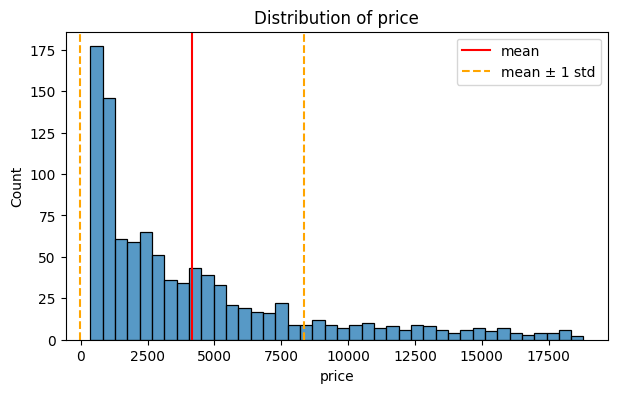

In [35]:
mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()
print("mean =", round(mean_price, 1), " std =", round(std_price, 1), " median =", diamonds_num['price'].median())

plt.figure(figsize=(7, 4))
sns.histplot(diamonds_num['price'], bins=40)
plt.axvline(mean_price, color='red', label='mean')
plt.axvline(mean_price - std_price, color='orange', linestyle='--', label='mean ± 1 std')
plt.axvline(mean_price + std_price, color='orange', linestyle='--')
plt.legend()
plt.title('Distribution of price')
plt.show()

### c) Normalization
Method :
*   Used StandardScaler on the 4 columns, since price (thousands) would otherwise dominate.
*   Printed the mean and std dev for each column




In [36]:
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)
print(diamonds_scaled.mean(axis=0).round(2), diamonds_scaled.std(axis=0).round(2))

[-0.  0. -0. -0.] [1. 1. 1. 1.]


### d) GMM + BIC curve
Requirement : Fit GMMs with different numbers of components and plot BIC.

Method :
*   Looped over 1 to 8 components. For each, fitted a GaussianMixture and saved its BIC in a list.
*   Plotted BIC vs number of components. Lower BIC = better balance between fitting the data and keeping the model simple.



1 components -> BIC = 9270.1
2 components -> BIC = 7589.3
3 components -> BIC = 7125.4
4 components -> BIC = 6977.1
5 components -> BIC = 7013.7
6 components -> BIC = 6987.7
7 components -> BIC = 7047.4
8 components -> BIC = 7173.2


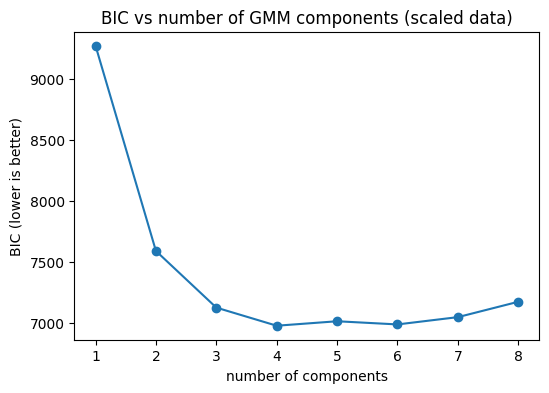

In [38]:
from sklearn import mixture
import matplotlib.pyplot as plt

bic = []
n_components_range = range(1, 9)

for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n, random_state=42)
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))
    print(n, "components -> BIC =", round(bic[-1], 1))

plt.figure(figsize=(6, 4))
plt.plot(list(n_components_range), bic, marker='o')
plt.xlabel('number of components'); plt.ylabel('BIC (lower is better)')
plt.title('BIC vs number of GMM components (scaled data)')
plt.show()

### e) Pick the minimum-BIC model
Method :
*   Used np.argmin to find the lowest BIC: 4 components.
*   Fitted the final GMM with 4 components and got the labels. Cluster sizes: 297, 248, 127, 328.
*   The curve is quite flat from 3 to 6, so 4 wins only narrowly.



In [39]:
best_n = int(np.argmin(bic)) + 1
print("Best number of components according to BIC:", best_n)

final_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = final_gmm.fit_predict(diamonds_scaled)
print("Sizes:", pd.Series(gmm_labels).value_counts().sort_index().to_dict())

Best number of components according to BIC: 4
Sizes: {0: 297, 1: 248, 2: 127, 3: 328}


### f) Pairplot + jointplot
Method :
*   Added the GMM labels to diamonds_num and made a pairplot coloured by cluster.
*   The clusters mostly split along carat and price (small/cheap to large/expensive) rather than forming clearly separate blobs.
*   As seen : without scaling, BIC chose 8, which shows scaling matters for GMM too.



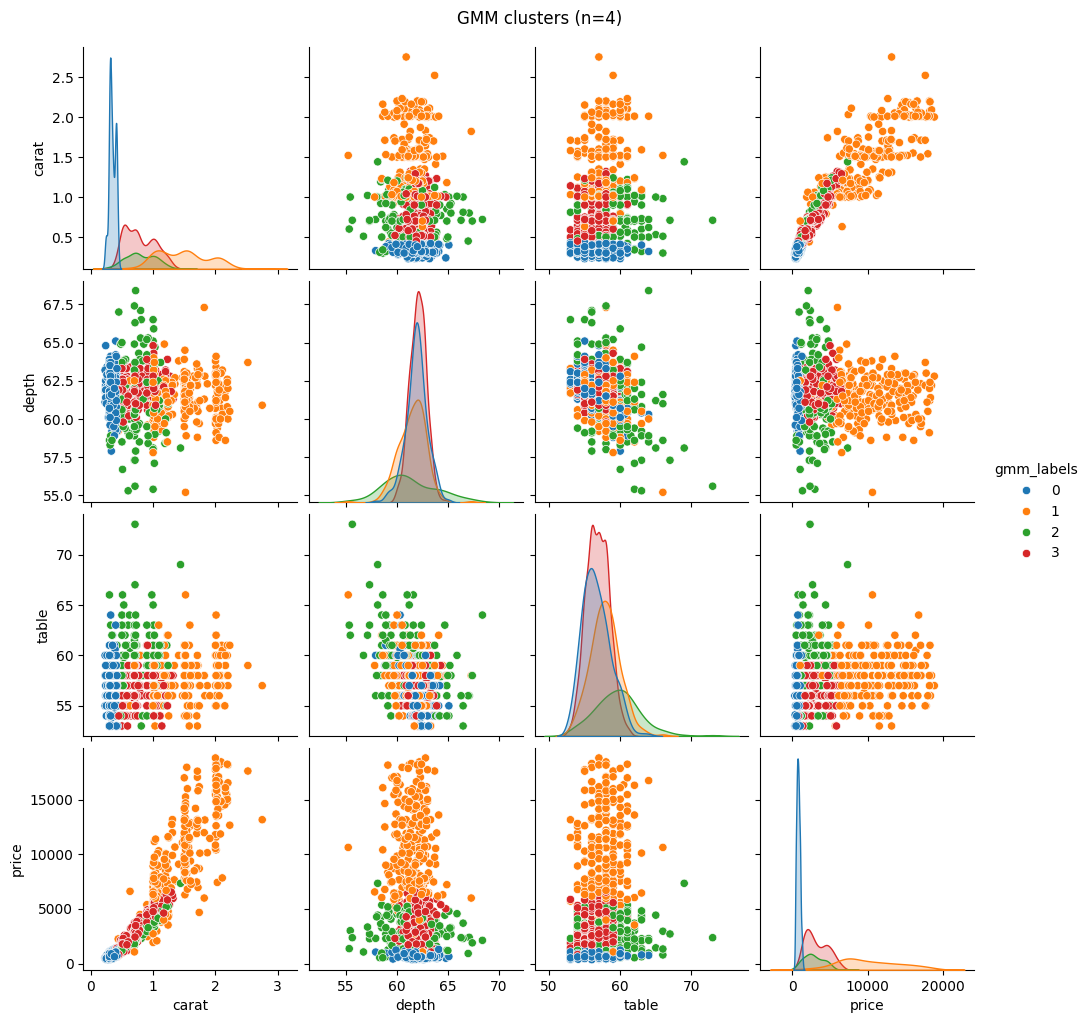

In [40]:
diamonds_num['gmm_labels'] = gmm_labels
sns.pairplot(diamonds_num, vars=['carat', 'depth', 'table', 'price'], hue='gmm_labels', palette='tab10')
plt.suptitle(f'GMM clusters (n={best_n})', y=1.02)
plt.show()

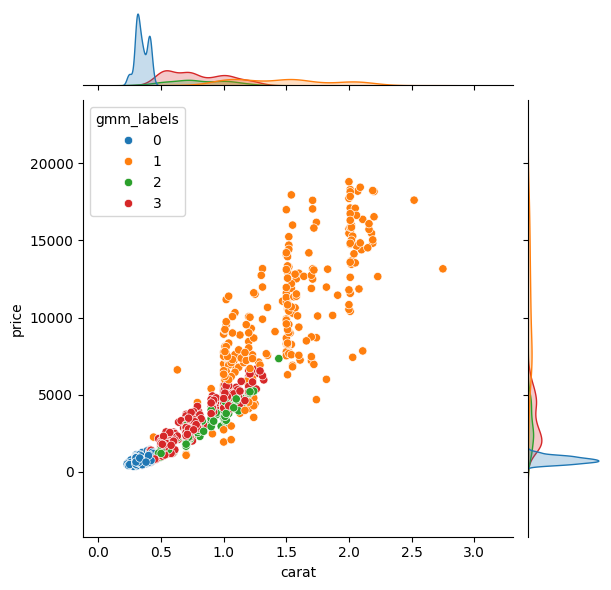

In [41]:
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_labels', palette='tab10')
plt.show()

## g) For answering thrid question in g - Repeat the BIC search on the raw (unscaled) values.


*   Checked the BIC curve: 4 is the lowest, but 4 to 6 are close.
*   Compared that with the pairplot: carat vs price shows the clearest groups.
*   Reran on raw data: BIC chose 8 instead of 4, so scaling changed the result.












In [42]:
bic_raw = []
for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n, random_state=42)
    gmm.fit(diamonds_num[['carat', 'depth', 'table', 'price']])
    bic_raw.append(gmm.bic(diamonds_num[['carat', 'depth', 'table', 'price']]))
print([round(b) for b in bic_raw])
print("Best n on RAW data:", int(np.argmin(bic_raw)) + 1)

[26865, 25191, 24721, 24752, 24715, 24752, 24791, 24694]
Best n on RAW data: 8


# g) Interpretation

*    Is 4 reasonable? Partly. BIC is lowest at 4, but 3 to 6 are close. In the pairplot, the 4 groups mostly cut the carat–price curve into cheap, medium and expensive diamonds rather than forming separate blobs.

*    Guessed by eye? No. The data looks like one continuous cloud, so I could have guessed 2 or 3.

*    Did normalizing change it? Yes. On raw data BIC chose 8, the top of the range, with no clear minimum, because price dominated. On scaled data it chose 4.